### Machine Learning Midterm - Wine Classification
- **Name:** Hamdi Küçük
- **ID:** 23040102043

In [47]:
import os
import platform

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import f_classif
from sklearn.metrics import (classification_report, confusion_matrix, roc_curve,
                             roc_auc_score, adjusted_rand_score)

import ml_helpers as helpers

DATASET_NAME = "wine"
SEEDS = [42, 52, 62]
TEST_SEED = 42            # test bölmesi ve son değerlendirme için önceden seçilen seed

os.makedirs("figures", exist_ok=True)
os.makedirs("results/supporting", exist_ok=True)
pd.set_option("display.max_rows", 120)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)

# Paket sürümlerini kaydediyoruz (tekrarlanabilirlik için)
print("Python      :", platform.python_version())
print("numpy       :", np.__version__)
print("pandas      :", pd.__version__)
print("scikit-learn:", sklearn.__version__)
print("matplotlib  :", matplotlib.__version__)
print("seaborn     :", sns.__version__)

Python      : 3.15.0
numpy       : 2.5.4
pandas      : 3.1.1
scikit-learn: 1.9.1
matplotlib  : 3.11.2
seaborn     : 0.13.2


### 1. Loading the Datasets
### 1.1 Load both datasets from scikit-learn
Ödev iki veri setini de ister. Bu notebook **Wine Classification** veri setini `load_wine` ile yükler
diğer veri seti kendi notebook'unda aynı adımlarla işlenir.

In [48]:
data = load_wine()
print(data.DESCR[:600])

.. _wine_dataset:

Wine recognition dataset
------------------------

**Data Set Characteristics:**

:Number of Instances: 178
:Number of Attributes: 13 numeric, predictive attributes and the class
:Attribute Information:
    - Alcohol
    - Malic acid
    - Ash
    - Alcalinity of ash
    - Magnesium
    - Total phenols
    - Flavanoids
    - Nonflavanoid phenols
    - Proanthocyanins
    - Color intensity
    - Hue
    - OD280/OD315 of diluted wines
    - Proline
    - class:
        - class_0
        - class_1
        - class_2

:Summary Statistics:

============================= ==== =====


### 1.2 Create the data frames
Özellikleri (features) `X`, hedef değişkeni (target) `y` olarak ayırıyoruz. `X` içinde hedef sütunu **yoktur**.

In [49]:
X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target, name="target")
class_names = [str(name) for name in data.target_names]
class_labels = [int(label) for label in sorted(y.unique())]

print("Dataset shape (X):", X.shape)
print("Target shape (y) :", y.shape)
print("\nFeature names:", list(X.columns))
print("\nTarget labels:", class_labels)
print("Target names :", class_names)
X.head()

Dataset shape (X): (178, 13)
Target shape (y) : (178,)

Feature names: ['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline']

Target labels: [0, 1, 2]
Target names : ['class_0', 'class_1', 'class_2']


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


In [50]:
class_overview = pd.DataFrame({
    "label": class_labels,
    "class_name": [class_names[label] for label in class_labels],
    "n_samples": [int((y == label).sum()) for label in class_labels],
})
class_overview["percent"] = (100 * class_overview["n_samples"] / len(y)).round(2)
class_overview

,label,class_name,n_samples,percent
0,0,class_0,59,33.15
1,1,class_1,71,39.89
2,2,class_2,48,26.97


**Etiket eşlemesi:** Wine etiketleri olduğu gibi kalır: **0 = class_0, 1 = class_1, 2 = class_2**.
Bu üç sınıf, üç farklı üzüm çeşidinden (cultivar) gelen şarapları temsil eder.

**Yorum (Interpretation):** Veri setinde 178 örnek ve 13 sayısal özellik var (kimyasal ölçümler). Sınıf dağılımı: class_0 = 59 (%33.15), class_1 = 71 (%39.89),
class_2 = 48 (%26.97). Dağılım tam dengeli değil, bu yüzden bölmelerde `stratify` kullanıyoruz ve macro-F1'e bakıyoruz.
Veri seti küçük olduğu için alt kümeler de küçük olacak.

### 2. Dataset Quality Checks
### 2.1 Missing values and duplicates
Her sütundaki eksik değer sayısını ve tekrarlanan satır sayısını raporluyoruz.
Burada hiçbir şeyi doldurmuyoruz gerekirse doldurma işlemi Bölüm 5'te **sadece eğitim verisi** ile yapılır.

In [51]:
missing_table = pd.DataFrame({"missing_count": X.isna().sum()})
missing_table.loc["target"] = y.isna().sum()
print("Total missing values:", int(missing_table["missing_count"].sum()))
missing_table.T

Total missing values: 0


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
missing_count,0,0,0,0,0,0,0,0,0,0,0,0,0,0


In [52]:
n_duplicate_feature_rows = int(X.duplicated().sum())
n_duplicate_full_rows = int(pd.concat([X, y], axis=1).duplicated().sum())
print("Duplicate rows (features only)    :", n_duplicate_feature_rows)
print("Duplicate rows (features + target):", n_duplicate_full_rows)
if missing_table["missing_count"].sum() == 0:
    print("-> No missing values are present.")
if n_duplicate_feature_rows == 0:
    print("-> No duplicate rows are present.")

Duplicate rows (features only)    : 0
Duplicate rows (features + target): 0
-> No missing values are present.
-> No duplicate rows are present.


### 2.2 Potential outliers
Aykırı değerleri (outliers) iki basit yöntemle **sadece sayıyoruz**, silmiyoruz:
- **IQR yöntemi:** `Q1 - 1.5*IQR` altı veya `Q3 + 1.5*IQR` üstü değerler.
- **z-score yöntemi:** `|z| > 3` olan değerler, yani ortalamadan 3 standart sapmadan uzak olanlar.

In [53]:
q1 = X.quantile(0.25)
q3 = X.quantile(0.75)
iqr = q3 - q1
lower_limit = q1 - 1.5 * iqr
upper_limit = q3 + 1.5 * iqr
z_scores = (X - X.mean()) / X.std()

outlier_table = pd.DataFrame({
    "Q1": q1, "Q3": q3, "IQR": iqr,
    "lower_limit": lower_limit, "upper_limit": upper_limit,
    "n_outliers_IQR": ((X < lower_limit) | (X > upper_limit)).sum(),
    "n_outliers_z_gt_3": (z_scores.abs() > 3).sum(),
})
print("Rows with at least one IQR outlier:", int(((X < lower_limit) | (X > upper_limit)).any(axis=1).sum()))
outlier_table.sort_values("n_outliers_IQR", ascending=False).round(3)

Rows with at least one IQR outlier: 17


,Q1,Q3,IQR,lower_limit,upper_limit,n_outliers_IQR,n_outliers_z_gt_3
magnesium,88.000,107.000,19.000,59.500,135.500,4,2
alcalinity_of_ash,17.200,21.500,4.300,10.750,27.950,4,1
color_intensity,3.220,6.200,2.980,-1.250,10.670,4,1
malic_acid,1.602,3.082,1.480,-0.617,5.302,3,1
ash,2.210,2.558,0.348,1.689,3.079,3,3
proanthocyanins,1.250,1.950,0.700,0.200,3.000,2,1
hue,0.782,1.120,0.338,0.276,1.626,1,1
alcohol,12.362,13.678,1.315,10.390,15.650,0,0
total_phenols,1.742,2.800,1.057,0.156,4.386,0,0
nonflavanoid_phenols,0.270,0.438,0.167,0.019,0.689,0,0


### 2.3 Data types

In [54]:
dtype_table = pd.DataFrame({"dtype": X.dtypes.astype(str)})
n_numerical = X.select_dtypes(include="number").shape[1]
n_categorical = X.shape[1] - n_numerical
print("Numerical features  :", n_numerical)
print("Categorical features:", n_categorical)
print("Target dtype        :", y.dtype)
dtype_table.T

Numerical features  : 13
Categorical features: 0
Target dtype        : int64


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
dtype,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64


**Yorum (Interpretation):** - **Eksik değer ve tekrar:** Eksik değer yok, tekrarlanan satır yok (0). Bu yüzden imputation adımı eklenmeyecek.
- **Veri tipleri:** 13 özelliğin hepsi `float64` (sayısal), kategorik özellik yok (0). Ayrıca dikkat çeken bir veri kalitesi sorunu görmedik.
- **Aykırı değerler:** IQR kuralına göre sadece 17 satırda en az bir aykırı değer var. En çok magnesium, alcalinity_of_ash ve color_intensity'de görülüyor (her biri 4).
  z-score > 3 olan değer sayısı en fazla 3 (ash). Breast Cancer'a göre çok daha az aykırı değer var.
- **Algoritmalara etkisi:** Wine'da daha büyük sorun ölçek farkı: proline 278–1680 arasında, hue ise 0.48–1.71 arasında.
  Ölçeklenmemiş veride KNN ve K-Means mesafeleri neredeyse sadece proline ile belirlenir. Uç değerler K-Means merkezlerini çekebilir ve
  GaussianNB'nin sınıf bazlı ortalama/varyans tahminlerini etkileyebilir. Karar ağacı eşiklerle çalıştığı için daha az etkilenir.
  Uç değerler gerçek ölçümler olabileceği için silinmedi.

## 3. Exploratory Data Analysis (EDA)

> **Not:** Bölüm 2 ve 3 yalnızca **betimleyicidir (descriptive)**. Buradaki tüm-veri özetleri ile özellik seçimi,
> ön işleme (preprocessing) fit etme veya örnek silme yapılmaz. Tüm deneyler orijinal özelliklerin hepsini kullanır.

### 3.1 Descriptive statistics

In [55]:
descriptive_stats = pd.DataFrame({
    "mean": X.mean(),
    "median": X.median(),
    "min": X.min(),
    "max": X.max(),
    "std": X.std(),
    "Q1": X.quantile(0.25),
    "Q3": X.quantile(0.75),
})
descriptive_stats.to_csv(f"results/supporting/{DATASET_NAME}_descriptive_stats.csv")
descriptive_stats.round(4)

,mean,median,min,max,std,Q1,Q3
alcohol,13.0006,13.050,11.03,14.83,0.8118,12.3625,13.6775
malic_acid,2.3363,1.865,0.74,5.80,1.1171,1.6025,3.0825
ash,2.3665,2.360,1.36,3.23,0.2743,2.2100,2.5575
alcalinity_of_ash,19.4949,19.500,10.60,30.00,3.3396,17.2000,21.5000
magnesium,99.7416,98.000,70.00,162.00,14.2825,88.0000,107.0000
total_phenols,2.2951,2.355,0.98,3.88,0.6259,1.7425,2.8000
flavanoids,2.0293,2.135,0.34,5.08,0.9989,1.2050,2.8750
nonflavanoid_phenols,0.3619,0.340,0.13,0.66,0.1245,0.2700,0.4375
proanthocyanins,1.5909,1.555,0.41,3.58,0.5724,1.2500,1.9500
color_intensity,5.0581,4.690,1.28,13.00,2.3183,3.2200,6.2000


### 3.2 Class distribution and correlations

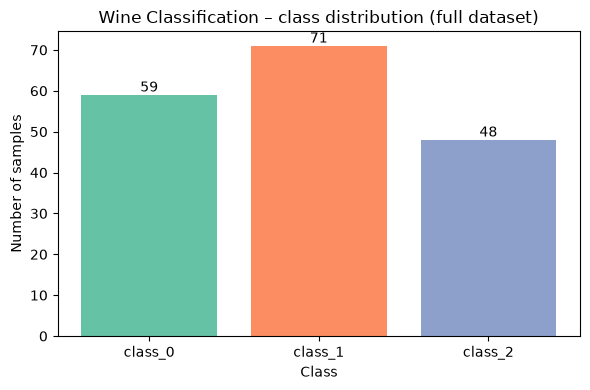

In [56]:
class_counts = y.value_counts().sort_index().rename(index={0: class_names[0], 1: class_names[1], 2: class_names[2]})
plt.figure(figsize=(6, 4))
bars = plt.bar(class_counts.index, class_counts.values, color=sns.color_palette("Set2", len(class_names)))
plt.bar_label(bars)
plt.title("Wine Classification – class distribution (full dataset)")
plt.xlabel("Class")
plt.ylabel("Number of samples")
plt.tight_layout()
plt.savefig(f"figures/{DATASET_NAME}_01_class_distribution.png", dpi=150)
plt.show()

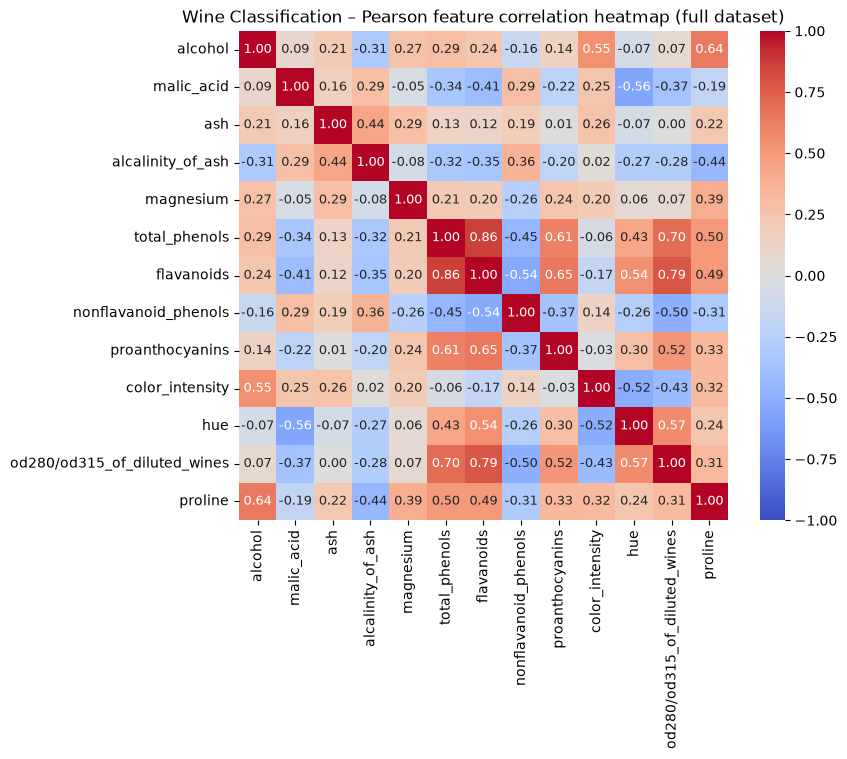

In [57]:
correlation = X.corr(method="pearson")
plt.figure(figsize=(9, 7.5))
sns.heatmap(correlation, cmap="coolwarm", vmin=-1, vmax=1, annot=True, fmt=".2f", square=True,
            annot_kws={"size": 9})
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)
plt.title("Wine Classification – Pearson feature correlation heatmap (full dataset)")
plt.tight_layout()
plt.savefig(f"figures/{DATASET_NAME}_02_correlation_heatmap.png", dpi=150)
plt.show()

En güçlü üç **benzersiz** özellik çiftini (mutlak korelasyona göre) buluyoruz. Köşegen (bir özelliğin kendisiyle korelasyonu = 1)
ve aynalanmış çiftler (A-B ile B-A aynı çifttir) hariç tutulur; bunun için sadece matrisin üst üçgenini kullanıyoruz.

In [58]:
upper_triangle = np.triu(np.ones(correlation.shape, dtype=bool), k=1)
pairs = correlation.where(upper_triangle).stack().reset_index()
pairs.columns = ["feature_1", "feature_2", "pearson_r"]
pairs["abs_r"] = pairs["pearson_r"].abs()
top3_pairs = pairs.sort_values("abs_r", ascending=False).head(3).reset_index(drop=True)
top3_pairs.to_csv(f"results/supporting/{DATASET_NAME}_top3_correlation_pairs.csv", index=False)
top3_pairs.round(4)

,feature_1,feature_2,pearson_r,abs_r
0,total_phenols,flavanoids,0.8646,0.8646
1,flavanoids,od280/od315_of_diluted_wines,0.7872,0.7872
2,total_phenols,od280/od315_of_diluted_wines,0.6999,0.6999


### 3.3 Boxplots
Özelliklerin ölçekleri çok farklı olduğu için her özelliği kendi küçük grafiğinde, sınıflara göre ayrılmış olarak çiziyoruz.

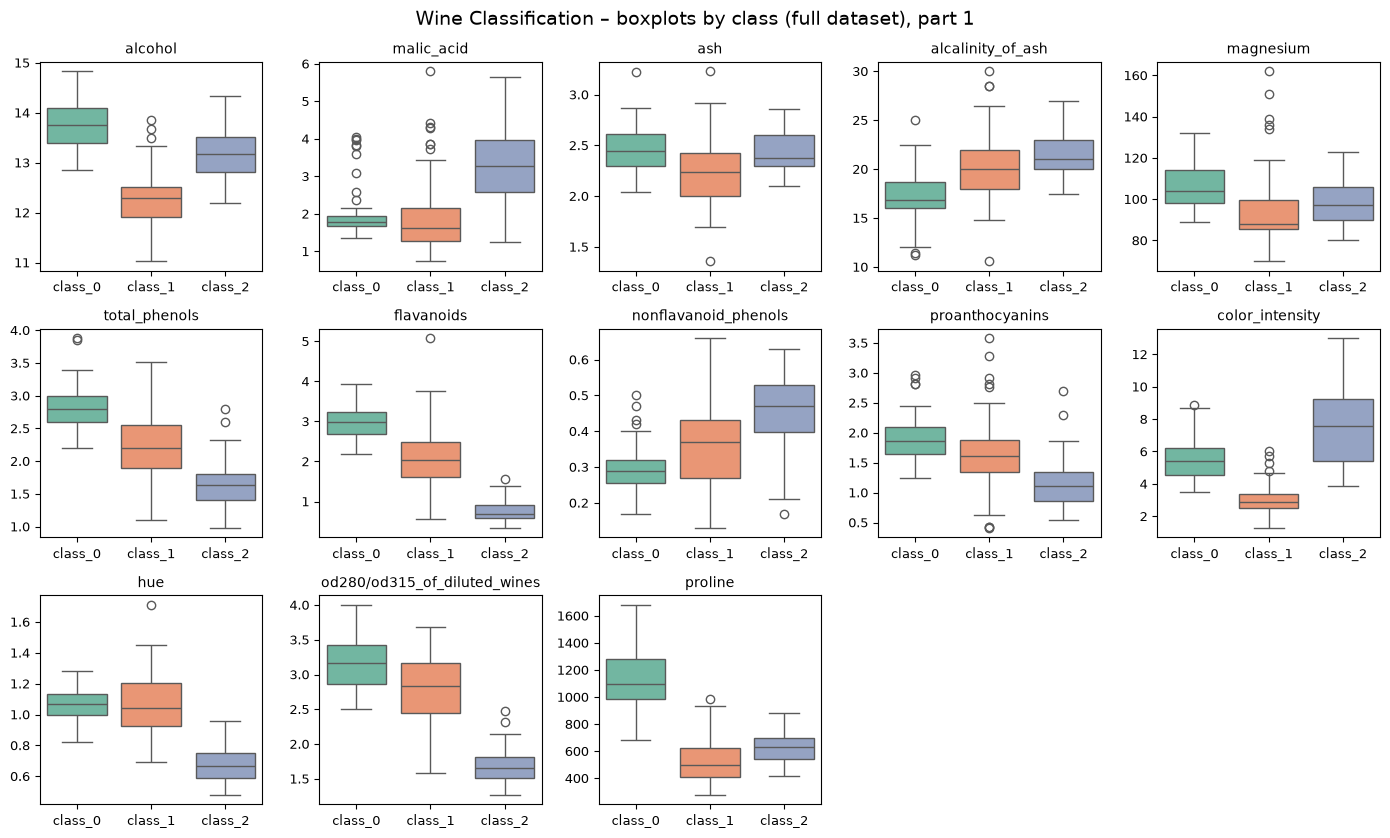

In [59]:
features = list(X.columns)
features_per_figure = 15
class_name_series = y.map({0: class_names[0], 1: class_names[1], 2: class_names[2]}).rename("class")

for figure_number, start in enumerate(range(0, len(features), features_per_figure), start=1):
    chunk = features[start:start + features_per_figure]
    fig, axes = plt.subplots(3, 5, figsize=(14, 8.5))
    axes = axes.flatten()
    for ax, feature in zip(axes, chunk):
        sns.boxplot(x=class_name_series, y=X[feature], hue=class_name_series, order=class_names,
                    palette="Set2", legend=False, ax=ax)
        ax.set_title(feature, fontsize=10)
        ax.tick_params(labelsize=9)
        ax.set_xlabel("")
        ax.set_ylabel("")
    for ax in axes[len(chunk):]:
        ax.axis("off")
    fig.suptitle(f"Wine Classification – boxplots by class (full dataset), part {figure_number}", fontsize=14)
    fig.tight_layout()
    fig.savefig(f"figures/{DATASET_NAME}_03_boxplots_part{figure_number}.png", dpi=120)
    plt.show()

**Yorum (Interpretation):** - **Korelasyon:** En güçlü üç benzersiz çift: total_phenols – flavanoids (r = 0.8646), flavanoids – od280/od315 (r = 0.7872) ve
  total_phenols – od280/od315 (r = 0.6999). Üçü de fenolik bileşiklerle ilgili ve birlikte artıp azalıyorlar. Bu özellikler bilgi tekrarı içerir.
- **Boxplot gözlemi 1:** Ölçekler çok farklı. proline yüzlerce–binler seviyesinde, hue ve nonflavanoid_phenols ise 1'in altında/civarında.
- **Boxplot gözlemi 2:** Bazı özellikler sınıfları çok iyi ayırıyor. flavanoids'te class_2 kutusu (≈0.6–0.9) diğerlerinden tamamen aşağıda;
  proline'da class_0 diğer iki sınıftan belirgin şekilde yüksek; color_intensity'de class_1 en düşük.
  ash ve magnesium'da ise sınıfların kutuları büyük ölçüde örtüşüyor.
- **Boxplot gözlemi 3:** class_1'de magnesium ve malic_acid gibi özelliklerde birkaç uç nokta var. class_0'da malic_acid için de birkaç uç nokta görülüyor.

## 4. Splitting the Datasets

### 4.1 Fix the test set and repeat the training/validation split
1. Önce verinin **%20'si test seti** olarak **bir kez** ayrılır (`random_state=42`, `stratify=y`). Bu test seti tüm ödev boyunca değişmez.
2. Kalan %80, her seed için (`42, 52, 62`) `test_size=0.125` ile eğitim ve doğrulama setlerine bölünür.
   0.80 × 0.125 = 0.10 olduğundan yaklaşık **%70 eğitim (training) / %10 doğrulama (validation) / %20 test** elde edilir.

Seed'ler yalnızca eğitim/doğrulama üyeliğini değiştirir; üç farklı test seti **oluşturmaz**.
`stratify` sınıf oranlarının her alt kümede korunmasını sağlar. DataFrame kullandığımız için orijinal satır indeksleri korunur.

In [60]:
X_rest, X_test, y_rest, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42)

splits = {}
for seed in SEEDS:
    X_train, X_val, y_train, y_val = train_test_split(
        X_rest, y_rest, test_size=0.125, stratify=y_rest, random_state=seed)
    splits[seed] = {
        "X_train": X_train, "X_val": X_val,
        "y_train": y_train, "y_val": y_val,
        "test_index": X_test.index.copy(),  
    }
    print(f"seed {seed}: train={len(X_train)}, validation={len(X_val)}, test={len(X_test)}")

seed 42: train=124, validation=18, test=36
seed 52: train=124, validation=18, test=36
seed 62: train=124, validation=18, test=36


### 4.2 Verify the split

In [61]:
summary_rows = []
for seed in SEEDS:
    subsets = {
        "train": splits[seed]["y_train"],
        "validation": splits[seed]["y_val"],
        "test": y_test,
    }
    for subset_name, labels in subsets.items():
        row = {"seed": seed, "subset": subset_name, "n_samples": len(labels),
               "percent_of_full": round(100 * len(labels) / len(y), 2)}
        for label in class_labels:
            row[f"n_{class_names[label]}"] = int((labels == label).sum())
        summary_rows.append(row)

split_summary = pd.DataFrame(summary_rows)
split_summary.to_csv(f"results/supporting/{DATASET_NAME}_split_summary.csv", index=False)
split_summary

,seed,subset,n_samples,percent_of_full,n_class_0,n_class_1,n_class_2
0,42,train,124,69.66,41,50,33
1,42,validation,18,10.11,6,7,5
2,42,test,36,20.22,12,14,10
3,52,train,124,69.66,41,50,33
4,52,validation,18,10.11,6,7,5
5,52,test,36,20.22,12,14,10
6,62,train,124,69.66,41,50,33
7,62,validation,18,10.11,6,7,5
8,62,test,36,20.22,12,14,10


In [62]:
for seed in SEEDS:
    train_idx = set(splits[seed]["X_train"].index)
    val_idx = set(splits[seed]["X_val"].index)
    test_idx = set(splits[seed]["test_index"])

    no_overlap = (len(train_idx & val_idx) == 0 and len(train_idx & test_idx) == 0 and len(val_idx & test_idx) == 0)
    total = len(train_idx) + len(val_idx) + len(test_idx)
    covers_all = (train_idx | val_idx | test_idx) == set(X.index)

    print(f"seed {seed}: no overlap = {no_overlap}, total = {total} (dataset = {len(X)}), covers all rows = {covers_all}")
    assert no_overlap and total == len(X) and covers_all

# test indeksleri her seed'de aynı mı?
first_seed_test = splits[SEEDS[0]]["test_index"]
same_test = True
for seed in SEEDS:
    if not splits[seed]["test_index"].equals(first_seed_test):
        same_test = False
        break

print("Test indices identical across all three seeds:", same_test)
assert same_test

seed 42: no overlap = True, total = 178 (dataset = 178), covers all rows = True
seed 52: no overlap = True, total = 178 (dataset = 178), covers all rows = True
seed 62: no overlap = True, total = 178 (dataset = 178), covers all rows = True
Test indices identical across all three seeds: True


In [63]:
index_rows = []

for seed in SEEDS:

    for row_index in splits[seed]["X_train"].index:
        index_rows.append({"seed": seed, "subset": "train", "row_index": int(row_index)})

    for row_index in splits[seed]["X_val"].index:
        index_rows.append({"seed": seed, "subset": "validation", "row_index": int(row_index)})

    for row_index in splits[seed]["test_index"]:
        index_rows.append({"seed": seed, "subset": "test", "row_index": int(row_index)})

split_indices = pd.DataFrame(index_rows)
split_indices.to_csv(f"results/{DATASET_NAME}_split_indices.csv", index=False)

print("Saved:", f"results/{DATASET_NAME}_split_indices.csv", "-", len(split_indices), "rows")
print("First 10 test row indices:", sorted(X_test.index)[:10])
print("First 10 training row indices (seed 42):", sorted(splits[42]["X_train"].index)[:10])

Saved: results/wine_split_indices.csv - 534 rows
First 10 test row indices: [7, 10, 14, 18, 20, 22, 28, 38, 42, 48]
First 10 training row indices (seed 42): [2, 3, 5, 8, 9, 11, 12, 13, 15, 16]


Aynı veri seti ve seed içinde **bütün algoritmalar, parametreler ve temsiller aynı eğitim/doğrulama indekslerini** kullanır,
çünkü hepsi `splits[seed]` sözlüğünden okunur. Üç tekrar birbiriyle örtüşebilir; bunlar üç bağımsız veri seti veya 3-fold
cross-validation değildir. Model seçimi sadece doğrulama sonuçlarıyla yapılır; final test için **seed 42 önceden** seçilmiştir.

**Yorum (Interpretation):** Her seed'de 124 eğitim (%69.66), 18 doğrulama (%10.11) ve 36 test (%20.22) örneği var; toplam 178.
Sınıf sayıları stratify sayesinde her seed'de aynı (eğitim 41/50/33, doğrulama 6/7/5, test 12/14/10), ama satırların kendisi değişiyor.
Örneğin seed 42 ve 52'nin doğrulama setleri 18 satırdan sadece 2'sini paylaşıyor. Kontrollerin hepsi geçti.
Doğrulama seti çok küçük (18 örnek): tek bir yanlış tahmin accuracy'yi yaklaşık 5.6 puan düşürür.

## 5. Data Preprocessing and Scaling

### 5.1 Handle missing values, if present

In [64]:
total_missing = int(X.isna().sum().sum())
if total_missing == 0:
    print("No missing values exist -> no imputation step is added.")
else:
    print("Missing values found:", total_missing, "-> a training-only imputer would be needed.")

No missing values exist -> no imputation step is added.


### 5.2 Select one scaler
Deneylerden **önce** tek bir ölçekleyici seçildi: **StandardScaler** (standardization).
Her özellikten eğitim ortalaması çıkarılır ve eğitim standart sapmasına bölünür: `z = (x - mean) / std`.
Böylece her özelliğin eğitim verisindeki ortalaması 0, standart sapması 1 olur. Aynı tür iki veri seti ve üç seed için kullanılır.
Ders notlarında da belirtildiği gibi, KNN ve K-Means gibi **mesafe tabanlı (distance-based)** algoritmalar ölçeğe duyarlıdır.

### 5.3 Fit and apply the scaler correctly
Her seed için **yeni** bir scaler oluşturulur ve **sadece o seed'in eğitim verisine** `fit` edilir.
Doğrulama verisi yalnızca `transform` edilir. Test verisi sadece seed 42 scaler'ı ile dönüştürülür. Hedef (`y`) ölçeklenmez.


In [65]:
scalers = {}
for seed in SEEDS:
    X_train = splits[seed]["X_train"]
    X_val = splits[seed]["X_val"]

    scaler = StandardScaler()
    scaler.fit(X_train)
    scalers[seed] = scaler

    X_train_scaled = pd.DataFrame(scaler.transform(X_train), index=X_train.index, columns=X.columns)
    X_val_scaled = pd.DataFrame(scaler.transform(X_val), index=X_val.index, columns=X.columns)

    splits[seed]["unscaled"] = {"train": X_train, "val": X_val}
    splits[seed]["scaled"] = {"train": X_train_scaled, "val": X_val_scaled}


X_test_scaled = pd.DataFrame(scalers[TEST_SEED].transform(X_test), index=X_test.index, columns=X.columns)
print("Fitted scalers in this notebook:", len(scalers))

Fitted scalers in this notebook: 3


In [66]:
print("Seed 42 – first five TRAINING rows BEFORE scaling:")
display(splits[42]["unscaled"]["train"].head().round(3))
print("Seed 42 – first five TRAINING rows AFTER StandardScaler:")
display(splits[42]["scaled"]["train"].head().round(3))

Seed 42 – first five TRAINING rows BEFORE scaling:


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
163,12.96,3.45,2.35,18.5,106.0,1.39,0.70,0.40,0.94,5.28,0.68,1.75,675.0
148,13.32,3.24,2.38,21.5,92.0,1.93,0.76,0.45,1.25,8.42,0.55,1.62,650.0
116,11.82,1.47,1.99,20.8,86.0,1.98,1.60,0.30,1.53,1.95,0.95,3.33,495.0
122,12.42,4.43,2.73,26.5,102.0,2.20,2.13,0.43,1.71,2.08,0.92,3.12,365.0
115,11.03,1.51,2.20,21.5,85.0,2.46,2.17,0.52,2.01,1.90,1.71,2.87,407.0


Seed 42 – first five TRAINING rows AFTER StandardScaler:


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
163,-0.018,1.089,-0.040,-0.308,0.433,-1.343,-1.322,0.353,-1.118,0.126,-1.227,-1.224,-0.209
148,0.440,0.892,0.073,0.609,-0.506,-0.491,-1.260,0.770,-0.572,1.512,-1.811,-1.415,-0.291
116,-1.465,-0.772,-1.397,0.395,-0.908,-0.412,-0.387,-0.482,-0.079,-1.344,-0.013,1.098,-0.800
122,-0.703,2.010,1.392,2.139,0.165,-0.065,0.165,0.603,0.238,-1.287,-0.147,0.789,-1.226
115,-2.469,-0.734,-0.605,0.609,-0.975,0.345,0.206,1.354,0.766,-1.367,3.405,0.422,-1.089


In [67]:
scaled_train_42 = splits[42]["scaled"]["train"]

train_mean_min = round(scaled_train_42.mean().min(), 4)
train_mean_max = round(scaled_train_42.mean().max(), 4)
print(f"Train mean - min: {train_mean_min}, max: {train_mean_max}")

train_std_min = round(scaled_train_42.std(ddof=0).min(), 4)
train_std_max = round(scaled_train_42.std(ddof=0).max(), 4)
print(f"Train std - min: {train_std_min}, max: {train_std_max}")

# validation seti scaler'a fit edilmediği için ortalaması tam 0 olmaz
val_mean_min = round(splits[42]["scaled"]["val"].mean().min(), 3)
val_mean_max = round(splits[42]["scaled"]["val"].mean().max(), 3)
print(f"Validation mean - min: {val_mean_min}, max: {val_mean_max}")

Train mean - min: -0.0, max: 0.0
Train std - min: 1.0, max: 1.0
Validation mean - min: -0.135, max: 0.403


**Yorum (Interpretation):** StandardScaler'dan sonra özellikler benzer aralıklara geldi. Örneğin 163 numaralı satırda proline 675.0'tan -0.209'a, hue 0.68'den -1.227'ye dönüştü.
Ölçekleme öncesinde proline'daki 100 birimlik fark, hue'daki her farktan çok daha büyük bir mesafe yaratıyordu. Ölçekleme sonrasında
her özelliğin katkısı birbirine yakın. Doğrulama ortalamaları tam 0 değil (-0.135 ile 0.403 arası), çünkü scaler sadece eğitim verisine fit edildi.

## 6. Preparing the Two Data Representations

Her seed için iki temsil (representation) vardır:
- **unscaled:** orijinal özelliklerin hepsi (eksik değer olmadığı için imputation yok),
- **scaled:** aynı özellikler ve aynı satırlar, Bölüm 5'teki StandardScaler sonrası.

Ölçeklemenin etkisini görebilmek için diğer bütün ayarlar aynı tutulur. Boyut indirgeme veya özellik seçimi yapılmaz.

In [68]:
for seed in SEEDS:
    for subset in ["train", "val"]:
        unscaled = splits[seed]["unscaled"][subset]
        scaled = splits[seed]["scaled"][subset]

        same_rows = unscaled.index.equals(scaled.index)
        same_columns = list(unscaled.columns) == list(scaled.columns)

        print(f"Seed {seed} - {subset}: Shape {unscaled.shape}, Same rows: {same_rows}, Same columns: {same_columns}")

Seed 42 - train: Shape (124, 13), Same rows: True, Same columns: True
Seed 42 - val: Shape (18, 13), Same rows: True, Same columns: True
Seed 52 - train: Shape (124, 13), Same rows: True, Same columns: True
Seed 52 - val: Shape (18, 13), Same rows: True, Same columns: True
Seed 62 - train: Shape (124, 13), Same rows: True, Same columns: True
Seed 62 - val: Shape (18, 13), Same rows: True, Same columns: True


## 7. Training the Classification Models

### 7.1 Required experiments
| Algorithm | Required settings | Fits (this dataset) |
|---|---|---|
| Decision Tree | max_depth = 2, 3, 5, 10, None; random_state = seed | 5 × 2 × 3 = 30 |
| KNN | n_neighbors = 1, 3, 5, 7, 11; uniform weights; Euclidean distance | 5 × 2 × 3 = 30 |
| Gaussian Naive Bayes | default settings | 1 × 2 × 3 = 6 |

Toplam **66** çalıştırma (run). 66 hücre yazmak yerine `ml_helpers.run_classifier_experiments` fonksiyonu
seed → temsil → model sırasıyla iç içe **döngülerle** tüm deneyleri çalıştırır. Her model sadece eğitim verisi ile `fit` edilir.
KNN ve GaussianNB `random_state` almaz; bu modellerde tekrarlar arasındaki fark sadece değişen eğitim/doğrulama üyeliğinden gelir.

In [69]:
run_table, seed42_models = helpers.run_classifier_experiments(DATASET_NAME, splits, SEEDS)
print("Number of classifier runs:", len(run_table))
print(run_table.groupby(["algorithm", "representation"]).size())
assert len(run_table) == 66

Number of classifier runs: 66
algorithm     representation
DecisionTree  scaled            15
              unscaled          15
GaussianNB    scaled             3
              unscaled           3
KNN           scaled            15
              unscaled          15
dtype: int64


### 7.2 Record and compare the experiments
Her çalıştırmanın bir **deney kimliği (experiment ID)** vardır: `veri seti_algoritma_temsil_parametre_seed`,
örneğin `wine_knn_scaled_k5_s42`. Seed, kimliğin bir parçasıdır; optimize edilen bir parametre değildir.
Düşük skorlu çalıştırmalar dahil hepsi kaydedilir. Seed 42 modelleri `seed42_models` sözlüğünde final test için saklanır.

In [70]:
print("Stored seed-42 fitted models:", len(seed42_models))
run_table[["run_id", "seed", "algorithm", "representation", "parameter",
           "train_accuracy", "train_f1_macro"]].head(12).round(4)

Stored seed-42 fitted models: 22


,run_id,seed,algorithm,representation,parameter,train_accuracy,train_f1_macro
0,wine_dt_unscaled_depth2_s42,42,DecisionTree,unscaled,max_depth=2,0.9355,0.9297
1,wine_dt_unscaled_depth3_s42,42,DecisionTree,unscaled,max_depth=3,0.9919,0.9926
2,wine_dt_unscaled_depth5_s42,42,DecisionTree,unscaled,max_depth=5,1.0000,1.0000
3,wine_dt_unscaled_depth10_s42,42,DecisionTree,unscaled,max_depth=10,1.0000,1.0000
4,wine_dt_unscaled_depthNone_s42,42,DecisionTree,unscaled,max_depth=None,1.0000,1.0000
5,wine_knn_unscaled_k1_s42,42,KNN,unscaled,n_neighbors=1,1.0000,1.0000
6,wine_knn_unscaled_k3_s42,42,KNN,unscaled,n_neighbors=3,0.8468,0.8415
7,wine_knn_unscaled_k5_s42,42,KNN,unscaled,n_neighbors=5,0.7984,0.7837
8,wine_knn_unscaled_k7_s42,42,KNN,unscaled,n_neighbors=7,0.8145,0.8071
9,wine_knn_unscaled_k11_s42,42,KNN,unscaled,n_neighbors=11,0.7500,0.7405


## 8. Measuring Validation Performance

### 8.1 Required metrics
Her çalıştırma kendi **doğrulama (validation)** alt kümesinde ölçülür: accuracy, macro precision, macro recall, macro F1 ve ROC-AUC.
- Precision/recall/F1 için `average="macro"`: her sınıfın skoru ayrı hesaplanır ve sınıflar eşit ağırlıkla ortalanır.
- `zero_division=0` kullanılır; ama bundan **önce** tanımsız (undefined) precision/recall olan sınıflar kaydedilir.
- **ROC-AUC (Wine):** sınıf olasılıkları ile `multi_class="ovr"` (one-vs-rest) ve `average="macro"`.
  Olasılık sütunlarının sırası `model.classes_` ile kontrol edilir. Sert (hard) tahminlerden ROC-AUC hesaplanmaz.

In [71]:
# Olasılık sütun sırası kontrolü
for config_id in ["dt_unscaled_depth2", "knn_scaled_k5", "gnb_scaled_default"]:
    print(config_id, "-> classes_ =", [int(c) for c in seed42_models[config_id].classes_])

undefined_runs = run_table[run_table["val_undefined_before_zero_division"] != ""]
print("\nRuns with an undefined precision/recall before zero_division:", len(undefined_runs))
undefined_runs[["run_id", "val_undefined_before_zero_division"]]

dt_unscaled_depth2 -> classes_ = [0, 1, 2]
knn_scaled_k5 -> classes_ = [0, 1, 2]
gnb_scaled_default -> classes_ = [0, 1, 2]

Runs with an undefined precision/recall before zero_division: 0


,run_id,val_undefined_before_zero_division


### 8.2 Comparison tables and model selection
**66 satırlık çalıştırma tablosu (run-level validation table):** 22 konfigürasyon × 3 seed.

In [72]:
run_columns = ["run_id", "seed", "algorithm", "representation", "parameter",
               "train_accuracy", "train_f1_macro", "val_accuracy", "val_precision_macro",
               "val_recall_macro", "val_f1_macro", "val_roc_auc"]
run_table[run_columns].round(4)

,run_id,seed,algorithm,representation,parameter,train_accuracy,train_f1_macro,val_accuracy,val_precision_macro,val_recall_macro,val_f1_macro,val_roc_auc
0,wine_dt_unscaled_depth2_s42,42,DecisionTree,unscaled,max_depth=2,0.9355,0.9297,0.8333,0.8631,0.8111,0.8175,0.9106
1,wine_dt_unscaled_depth3_s42,42,DecisionTree,unscaled,max_depth=3,0.9919,0.9926,0.9444,0.9583,0.9444,0.9475,0.9686
2,wine_dt_unscaled_depth5_s42,42,DecisionTree,unscaled,max_depth=5,1.0000,1.0000,0.9444,0.9583,0.9444,0.9475,0.9571
3,wine_dt_unscaled_depth10_s42,42,DecisionTree,unscaled,max_depth=10,1.0000,1.0000,0.9444,0.9583,0.9444,0.9475,0.9571
4,wine_dt_unscaled_depthNone_s42,42,DecisionTree,unscaled,max_depth=None,1.0000,1.0000,0.9444,0.9583,0.9444,0.9475,0.9571
5,wine_knn_unscaled_k1_s42,42,KNN,unscaled,n_neighbors=1,1.0000,1.0000,0.6667,0.6750,0.6603,0.6646,0.7452
6,wine_knn_unscaled_k3_s42,42,KNN,unscaled,n_neighbors=3,0.8468,0.8415,0.6111,0.6111,0.6016,0.6041,0.8003
7,wine_knn_unscaled_k5_s42,42,KNN,unscaled,n_neighbors=5,0.7984,0.7837,0.7222,0.7159,0.7159,0.7128,0.8759
8,wine_knn_unscaled_k7_s42,42,KNN,unscaled,n_neighbors=7,0.8145,0.8071,0.6667,0.6714,0.6683,0.6605,0.8405
9,wine_knn_unscaled_k11_s42,42,KNN,unscaled,n_neighbors=11,0.7500,0.7405,0.6111,0.6159,0.6016,0.5998,0.8198


**22 satırlık özet:** Aynı algoritma + temsil + parametre için üç seed'in **ortalaması (mean)** ve **örneklem standart sapması
(sample standard deviation, ddof=1)**. pandas'ın `std()` fonksiyonu varsayılan olarak ddof=1 kullanır.

In [73]:
metric_columns = ["train_accuracy", "train_f1_macro", "val_accuracy", "val_precision_macro",
                  "val_recall_macro", "val_f1_macro", "val_roc_auc"]
group_columns = ["config_id", "algorithm", "representation", "parameter"]

means = run_table.groupby(group_columns)[metric_columns].mean().add_suffix("_mean")
stds = run_table.groupby(group_columns)[metric_columns].std(ddof=1).add_suffix("_std")

summary_table = pd.concat([means, stds], axis=1).reset_index()
summary_table["n_seeds"] = run_table.groupby(group_columns).size().values
summary_table.insert(0, "dataset", DATASET_NAME)

print("Summary rows:", len(summary_table))
assert len(summary_table) == 22

display_cols = ["config_id"] + [c for c in summary_table.columns if c.endswith("_mean") or c.endswith("_std")]
summary_table[display_cols].round(4)

Summary rows: 22


,config_id,train_accuracy_mean,train_f1_macro_mean,val_accuracy_mean,val_precision_macro_mean,val_recall_macro_mean,val_f1_macro_mean,val_roc_auc_mean,train_accuracy_std,train_f1_macro_std,val_accuracy_std,val_precision_macro_std,val_recall_macro_std,val_f1_macro_std,val_roc_auc_std
0,dt_scaled_depth10,1.0000,1.0000,0.9444,0.9614,0.9407,0.9462,0.9552,0.0000,0.0000,0.0556,0.0371,0.0612,0.0545,0.0457
1,dt_scaled_depth2,0.9355,0.9365,0.8519,0.8724,0.8487,0.8481,0.9050,0.0081,0.0106,0.0321,0.0214,0.0495,0.0365,0.0219
2,dt_scaled_depth3,0.9919,0.9926,0.9444,0.9614,0.9407,0.9462,0.9611,0.0000,0.0000,0.0556,0.0371,0.0612,0.0545,0.0431
3,dt_scaled_depth5,1.0000,1.0000,0.9444,0.9614,0.9407,0.9462,0.9552,0.0000,0.0000,0.0556,0.0371,0.0612,0.0545,0.0457
4,dt_scaled_depthNone,1.0000,1.0000,0.9444,0.9614,0.9407,0.9462,0.9552,0.0000,0.0000,0.0556,0.0371,0.0612,0.0545,0.0457
5,dt_unscaled_depth10,1.0000,1.0000,0.9444,0.9614,0.9407,0.9462,0.9552,0.0000,0.0000,0.0556,0.0371,0.0612,0.0545,0.0457
6,dt_unscaled_depth2,0.9355,0.9365,0.8519,0.8724,0.8487,0.8481,0.9050,0.0081,0.0106,0.0321,0.0214,0.0495,0.0365,0.0219
7,dt_unscaled_depth3,0.9919,0.9926,0.9444,0.9614,0.9407,0.9462,0.9611,0.0000,0.0000,0.0556,0.0371,0.0612,0.0545,0.0431
8,dt_unscaled_depth5,1.0000,1.0000,0.9444,0.9614,0.9407,0.9462,0.9552,0.0000,0.0000,0.0556,0.0371,0.0612,0.0545,0.0457
9,dt_unscaled_depthNone,1.0000,1.0000,0.9444,0.9614,0.9407,0.9462,0.9552,0.0000,0.0000,0.0556,0.0371,0.0612,0.0545,0.0457


**Model seçimi (sadece doğrulama sonuçlarıyla):** en yüksek ortalama doğrulama macro-F1. Eşitlik olursa sırasıyla:
daha yüksek ortalama doğrulama accuracy → daha düşük macro-F1 standart sapması → alfabetik konfigürasyon kimliği.
Test sonuçları veya en iyi tek seed seçimde **kullanılmaz**.

In [74]:
ranking = summary_table.sort_values(
    by=["val_f1_macro_mean", "val_accuracy_mean", "val_f1_macro_std", "config_id"],
    ascending=[False, False, True, True]).reset_index(drop=True)
selected_row = ranking.iloc[0]
selected_config = selected_row["config_id"]
selected_representation = selected_row["representation"]
print("SELECTED CONFIGURATION:", selected_config)
print("Mean validation macro-F1: %.4f (std %.4f)" % (selected_row["val_f1_macro_mean"], selected_row["val_f1_macro_std"]))
ranking[["config_id", "val_f1_macro_mean", "val_f1_macro_std", "val_accuracy_mean", "val_roc_auc_mean"]].head(8).round(4)

SELECTED CONFIGURATION: knn_scaled_k11
Mean validation macro-F1: 0.9814 (std 0.0323)


,config_id,val_f1_macro_mean,val_f1_macro_std,val_accuracy_mean,val_roc_auc_mean
0,knn_scaled_k11,0.9814,0.0323,0.9815,1.0000
1,knn_scaled_k5,0.9814,0.0323,0.9815,1.0000
2,knn_scaled_k7,0.9814,0.0323,0.9815,1.0000
3,knn_scaled_k1,0.9658,0.0296,0.9630,0.9749
4,gnb_scaled_default,0.9638,0.0314,0.9630,1.0000
5,gnb_unscaled_default,0.9638,0.0314,0.9630,1.0000
6,dt_scaled_depth10,0.9462,0.0545,0.9444,0.9552
7,dt_scaled_depth3,0.9462,0.0545,0.9444,0.9611


**Ölçeklemenin etkisi:** Aynı ayarın scaled ve unscaled ortalama doğrulama macro-F1 değerlerini yan yana koyuyoruz.
`gap` sütunu ortalama eğitim macro-F1 ile ortalama doğrulama macro-F1 arasındaki farktır (büyük fark → aşırı öğrenme / overfitting işareti).

In [75]:
summary_table["setting"] = summary_table["algorithm"] + " " + summary_table["parameter"]
scaling_effect = summary_table.pivot(index="setting", columns="representation", values="val_f1_macro_mean")
scaling_effect["scaled_minus_unscaled"] = scaling_effect["scaled"] - scaling_effect["unscaled"]
gap = summary_table.pivot(index="setting", columns="representation", values="train_f1_macro_mean") - \
      summary_table.pivot(index="setting", columns="representation", values="val_f1_macro_mean")
scaling_effect["gap_unscaled"] = gap["unscaled"]
scaling_effect["gap_scaled"] = gap["scaled"]
scaling_effect.round(4)

representation,scaled,unscaled,scaled_minus_unscaled,gap_unscaled,gap_scaled
setting,,,,,
DecisionTree max_depth=10,0.9462,0.9462,0.0000,0.0538,0.0538
DecisionTree max_depth=2,0.8481,0.8481,0.0000,0.0883,0.0883
DecisionTree max_depth=3,0.9462,0.9462,0.0000,0.0464,0.0464
DecisionTree max_depth=5,0.9462,0.9462,0.0000,0.0538,0.0538
DecisionTree max_depth=None,0.9462,0.9462,0.0000,0.0538,0.0538
GaussianNB default,0.9638,0.9638,0.0000,0.0201,0.0201
KNN n_neighbors=1,0.9658,0.6714,0.2944,0.3286,0.0342
KNN n_neighbors=11,0.9814,0.6005,0.3809,0.1304,-0.0158
KNN n_neighbors=3,0.9457,0.6456,0.3002,0.1838,0.0230


**Parametre karşılaştırma grafikleri:** ağaç derinliği ve KNN komşu sayısına göre ortalama eğitim ve doğrulama macro-F1.
Hata çubukları (error bars) üç seed'in standart sapmasıdır. Scaled ve unscaled noktalar üst üste binmesin diye yatayda biraz kaydırılmıştır;
karar ağacında iki temsilin değerleri birebir aynı olduğu için iki çizgi aynı yükseklikte görünür.

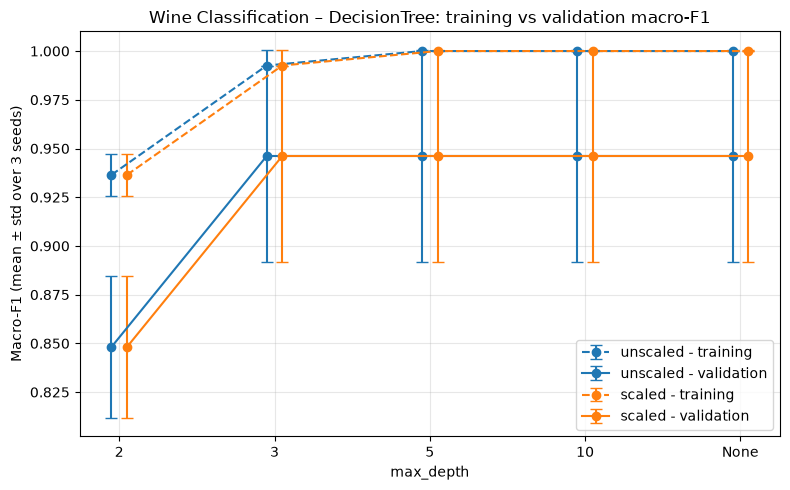

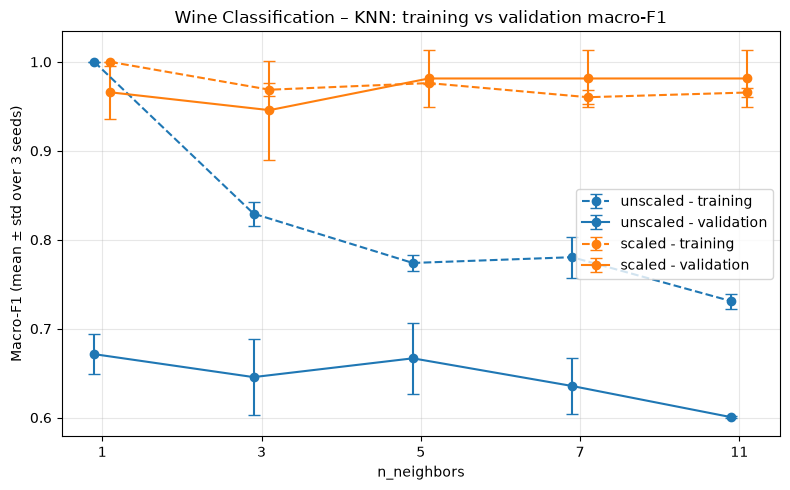

In [76]:
def plot_parameter_curve(algorithm, param_name, param_values, file_name):
    plt.figure(figsize=(8, 5))
    positions = np.arange(len(param_values))

    param_strings = []
    for val in param_values:
        param_strings.append(f"{param_name}={val}")

    part_unscaled = summary_table[(summary_table["algorithm"] == algorithm) & (summary_table["representation"] == "unscaled")]
    part_unscaled = part_unscaled.set_index("parameter").loc[param_strings]

    part_scaled = summary_table[(summary_table["algorithm"] == algorithm) & (summary_table["representation"] == "scaled")]
    part_scaled = part_scaled.set_index("parameter").loc[param_strings]

    plt.errorbar(positions - 0.05, part_unscaled["train_f1_macro_mean"], yerr=part_unscaled["train_f1_macro_std"],
                 color="tab:blue", linestyle="--", marker="o", capsize=4, label="unscaled - training")

    plt.errorbar(positions - 0.05, part_unscaled["val_f1_macro_mean"], yerr=part_unscaled["val_f1_macro_std"],
                 color="tab:blue", linestyle="-", marker="o", capsize=4, label="unscaled - validation")

    plt.errorbar(positions + 0.05, part_scaled["train_f1_macro_mean"], yerr=part_scaled["train_f1_macro_std"],
                 color="tab:orange", linestyle="--", marker="o", capsize=4, label="scaled - training")

    plt.errorbar(positions + 0.05, part_scaled["val_f1_macro_mean"], yerr=part_scaled["val_f1_macro_std"],
                 color="tab:orange", linestyle="-", marker="o", capsize=4, label="scaled - validation")

    plt.xticks(positions, [str(v) for v in param_values])
    plt.xlabel(param_name)
    plt.ylabel("Macro-F1 (mean ± std over 3 seeds)")
    plt.title(f"Wine Classification – {algorithm}: training vs validation macro-F1")
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.savefig(f"figures/{DATASET_NAME}_{file_name}.png", dpi=150)
    plt.show()

plot_parameter_curve("DecisionTree", "max_depth", helpers.TREE_DEPTHS, "04_tree_depth_comparison")
plot_parameter_curve("KNN", "n_neighbors", helpers.NEIGHBOR_COUNTS, "05_knn_neighbors_comparison")

Not: Standart sapma sadece bu üç tekrarlanan bölünmedeki değişkenliği anlatır; güven aralığı (confidence interval)
veya istatistiksel anlamlılık kanıtı değildir.

**Yorum (Interpretation):** - **Seçilen konfigürasyon:** `knn_scaled_k11` (ortalama doğrulama macro-F1 = 0.9814, std = 0.0323). `knn_scaled_k5` ve `knn_scaled_k7`
  ile ortalama macro-F1 (0.9814), ortalama accuracy (0.9815) ve standart sapma (0.0323) **tamamen eşit**. Bu yüzden son kural olan
  alfabetik sıra uygulandı. Metin olarak "knn_scaled_k11", "knn_scaled_k5"ten önce gelir. Yani bu seçim k=11'in daha iyi olduğunu göstermez; sadece eşitlik kuralının sonucudur.
- **Ölçekleme etkisi:** KNN çok büyük fark gösterdi: k=11 için 0.6005 → 0.9814 (+0.3809), k=1 için 0.6714 → 0.9658 (+0.2944).
  Ölçeklenmemiş veride proline mesafeyi domine ediyor. Karar ağacı ve GaussianNB'de scaled ve unscaled sonuçlar aynı (fark 0.0000).
- **Ağaç derinliği:** max_depth=2'de ortalama doğrulama macro-F1 0.8481; 3, 5, 10 ve None'da 0.9462 ve hepsi aynı. Yani derinlik 3'ten sonra
  doğrulama sonucu değişmedi, ama eğitim macro-F1 1.0'a çıktı (depth 5 ve üstü).
- **Komşu sayısı:** Scaled KNN'de k=1: 0.9658, k=3: 0.9457, k=5/7/11: 0.9814. Unscaled KNN'de k büyüdükçe eğitim macro-F1 0.83'ten (k=3) 0.73'e (k=11) düştü
  ve doğrulama skorları 0.60–0.67 aralığında kaldı. Yani daha büyük k her zaman daha iyi sonuç vermedi.
- **Eğitim–doğrulama farkı:** Unscaled KNN k=1'de çok büyük (0.3286): model eğitimi ezberliyor ama genelleyemiyor. Scaled KNN'de fark küçük, hatta
  bazı k değerlerinde negatif (doğrulama skoru eğitimden biraz yüksek). Bu, 18 örneklik doğrulama setinde şansın etkisini gösterir.
- **Seed'ler arası değişkenlik:** Karar ağacının std değeri 0.0545 (seed'lere göre 0.947, 1.000, 0.891). Seçilen KNN'de değerler 1.000, 1.000, 0.944.
  18 örnekte tek bir hata büyük fark yarattığı için standart sapmalar ortalamalar arasındaki farklarla aynı büyüklükte.

## 9. Evaluating the Selected Models on the Test Sets

Seçim artık **dondurulmuştur (frozen)**. Seçilen konfigürasyonun sadece **seed 42** ile eğitilmiş modeli, seed 42 ön işlemesiyle
sabit test setinde bir kez değerlendirilir. Eğitim + doğrulama ile yeniden eğitim yapılmaz, başka aday test edilmez.

### 9.1 Final performance metrics

In [77]:
final_model = seed42_models[selected_config]

if selected_representation == "scaled":
    X_test_used = X_test_scaled
else:
    X_test_used = X_test

print(f"Final model: {selected_config}")
print(f"Representation: {selected_representation}")
print(f"Evaluation seed: {TEST_SEED}")

classes_list = [int(c) for c in final_model.classes_]
print(f"Probability column order (classes_): {classes_list}")

test_pred = final_model.predict(X_test_used)
test_proba = final_model.predict_proba(X_test_used)
test_scores = helpers.classification_metrics(y_test, test_pred, test_proba, final_model.classes_, DATASET_NAME)

undefined_classes = helpers.undefined_metric_classes(y_test.values, test_pred, final_model.classes_)
print(f"Undefined precision/recall on test (before zero_division): {undefined_classes}")

for name, value in test_scores.items():
    print(f"test {name}: {value:.4f}")

Final model: knn_scaled_k11
Representation: scaled
Evaluation seed: 42
Probability column order (classes_): [0, 1, 2]
Undefined precision/recall on test (before zero_division): 
test accuracy: 1.0000
test precision_macro: 1.0000
test recall_macro: 1.0000
test f1_macro: 1.0000
test roc_auc: 1.0000


In [78]:
report_text = classification_report(y_test, test_pred, labels=class_labels, target_names=class_names, digits=4, zero_division=0)

report_dict = classification_report(y_test, test_pred, labels=class_labels, target_names=class_names, output_dict=True, zero_division=0)

report_df = pd.DataFrame(report_dict).T
report_df.to_csv(f"results/supporting/{DATASET_NAME}_test_classification_report.csv")

print(f"Classification report - {DATASET_NAME} - {selected_config}")
print("Test set results (seed 42):")
print(report_text)

Classification report - wine - knn_scaled_k11
Test set results (seed 42):
              precision    recall  f1-score   support

     class_0     1.0000    1.0000    1.0000        12
     class_1     1.0000    1.0000    1.0000        14
     class_2     1.0000    1.0000    1.0000        10

    accuracy                         1.0000        36
   macro avg     1.0000    1.0000    1.0000        36
weighted avg     1.0000    1.0000    1.0000        36



In [79]:
final_test_table = pd.DataFrame([{
    "dataset": DATASET_NAME,
    "selected_config": selected_config,
    "evaluation_seed": TEST_SEED,
    "val_f1_macro_mean": selected_row["val_f1_macro_mean"],
    "val_f1_macro_std": selected_row["val_f1_macro_std"],
    "test_accuracy": test_scores["accuracy"],
    "test_precision_macro": test_scores["precision_macro"],
    "test_recall_macro": test_scores["recall_macro"],
    "test_f1_macro": test_scores["f1_macro"],
    "test_roc_auc": test_scores["roc_auc"]
}])

seed42_val = run_table[run_table["run_id"] == f"{DATASET_NAME}_{selected_config}_s42"]
val_f1_score = seed42_val["val_f1_macro"].iloc[0]

print(f"Seed-42 validation macro-F1 of this model: {val_f1_score:.4f}")

final_test_table.round(4)

Seed-42 validation macro-F1 of this model: 1.0000


,dataset,selected_config,evaluation_seed,val_f1_macro_mean,val_f1_macro_std,test_accuracy,test_precision_macro,test_recall_macro,test_f1_macro,test_roc_auc
0,wine,knn_scaled_k11,42,0.9814,0.0323,1.0,1.0,1.0,1.0,1.0


**Yorum (Interpretation):** Test setinde (36 örnek) tüm metrikler 1.0000: accuracy, macro precision, macro recall, macro-F1 ve ROC-AUC. Bu modelin seed-42 doğrulama macro-F1 değeri de 1.0;
üç seed ortalaması ise 0.9814. Test sonucu doğrulama sonuçlarıyla uyumlu, ama 36 örneklik tek bir testte hatasız olmak modelin her zaman hatasız olacağı anlamına gelmez
(bkz. 9.4). Seçilen model değiştirilmedi.

### 9.2 Confusion matrices
Satırlar **Actual** (gerçek sınıf), sütunlar **Predicted** (tahmin) olarak etiketlenir; hücrelerde sayılar (counts) vardır.

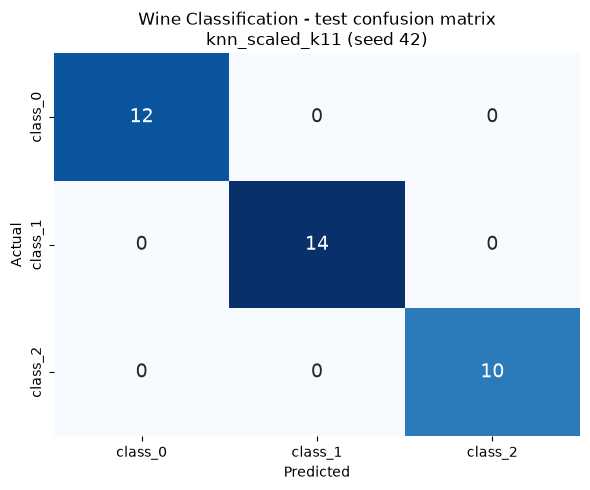

                Predicted class_0  Predicted class_1  Predicted class_2
Actual class_0                 12                  0                  0
Actual class_1                  0                 14                  0
Actual class_2                  0                  0                 10


In [80]:
cm = confusion_matrix(y_test, test_pred, labels=class_labels)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, annot_kws={"size": 14},
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title(f"Wine Classification - test confusion matrix\n{selected_config} (seed 42)")
plt.tight_layout()
plt.savefig(f"figures/{DATASET_NAME}_06_confusion_matrix_test.png", dpi=150)
plt.show()

actual_names = ["Actual " + n for n in class_names]
predicted_names = ["Predicted " + n for n in class_names]

cm_display = pd.DataFrame(cm, index=actual_names, columns=predicted_names)
print(cm_display)

cm_csv = pd.DataFrame(cm, index=class_names, columns=class_names)
cm_csv.to_csv(f"results/supporting/{DATASET_NAME}_test_confusion_matrix.csv")

Tam 3 × 3 matris yukarıdadır. Köşegen dışındaki (off-diagonal) en büyük hücre en sık yapılan karışıklığı gösterir.

In [81]:
off_diagonal = cm.copy()
np.fill_diagonal(off_diagonal, 0)
if off_diagonal.sum() == 0:
    print("There are no test errors: all off-diagonal cells are 0.")
else:
    actual_i, predicted_i = np.unravel_index(np.argmax(off_diagonal), off_diagonal.shape)
    print(f"Largest off-diagonal confusion: actual {class_names[actual_i]} predicted as "
          f"{class_names[predicted_i]} ({off_diagonal[actual_i, predicted_i]} samples)")
    print("Total test errors:", int(off_diagonal.sum()))

There are no test errors: all off-diagonal cells are 0.


**Elle hesap için seçilen sınıf: `class_1`** (en kalabalık sınıf; seçim sonuçlara bakmadan önceden yapıldı).
O sınıf "pozitif", diğer iki sınıf birlikte "negatif" kabul edilir (one-vs-rest).

In [82]:
chosen = 1
TP = cm[chosen, chosen]
FP = cm[:, chosen].sum() - TP      # başka sınıftan olup class_1 tahmin edilenler
FN = cm[chosen, :].sum() - TP      # class_1 olup başka sınıf tahmin edilenler
TN = cm.sum() - TP - FP - FN

print(f"class_1 vs rest: TP = {TP}, FP = {FP}, FN = {FN}, TN = {TN}")

if (TP + FP) > 0:
    manual_precision = TP / (TP + FP)
else:
    manual_precision = None

if (TP + FN) > 0:
    manual_recall = TP / (TP + FN)
else:
    manual_recall = None

if manual_precision is None or manual_recall is None or (manual_precision + manual_recall) == 0:
    manual_f1 = None
else:
    manual_f1 = 2 * manual_precision * manual_recall / (manual_precision + manual_recall)

if manual_precision is None:
    p_str = "undefined"
else:
    p_str = round(manual_precision, 4)

if manual_recall is None:
    r_str = "undefined"
else:
    r_str = round(manual_recall, 4)

if manual_f1 is None:
    f1_str = "undefined"
else:
    f1_str = round(manual_f1, 4)

print(f"Manual precision = TP/(TP+FP) = {TP}/({TP}+{FP}) = {p_str}")
print(f"Manual recall = TP/(TP+FN) = {TP}/({TP}+{FN}) = {r_str}")
print(f"Manual F1 = 2PR/(P+R) = {f1_str}")

rep_precision = report_dict["class_1"]["precision"]
rep_recall = report_dict["class_1"]["recall"]
rep_f1 = report_dict["class_1"]["f1-score"]

manual_check = pd.DataFrame({
    "manual": [manual_precision, manual_recall, manual_f1],
    "classification_report (class_1 row)": [rep_precision, rep_recall, rep_f1]
}, index=["precision", "recall", "f1"])

manual_check.to_csv(f"results/supporting/{DATASET_NAME}_manual_metric_check.csv")
manual_check.round(4)

class_1 vs rest: TP = 14, FP = 0, FN = 0, TN = 22
Manual precision = TP/(TP+FP) = 14/(14+0) = 1.0
Manual recall = TP/(TP+FN) = 14/(14+0) = 1.0
Manual F1 = 2PR/(P+R) = 1.0


,manual,classification_report (class_1 row)
precision,1.0,1.0
recall,1.0,1.0
f1,1.0,1.0


**Yorum (Interpretation):** 3 × 3 matrisin köşegeni 12, 14 ve 10; köşegen dışındaki hücrelerin hepsi 0. Bu test setinde **hiç karışıklık (confusion) yok**,
bu yüzden "en büyük köşegen dışı hata" örneği gösterilemiyor; bir örnek uydurmuyoruz.
Elle hesap (class_1 vs rest): TP = 14, FP = 0, FN = 0, TN = 22. Buradan precision = 14/14 = 1.0, recall = 14/14 = 1.0, F1 = 1.0 çıkıyor ve
classification report'taki **class_1 satırıyla** aynı. Paydalar sıfır olmadığı için tanımsız metrik yok.

### 9.3 ROC curves
ROC eğrisi farklı karar eşiklerinde (decision threshold) True Positive Rate ile False Positive Rate'i gösterir.
Bu grafik sadece betimleyicidir; test setiyle yeni eşik seçilmez veya model ayarlanmaz.

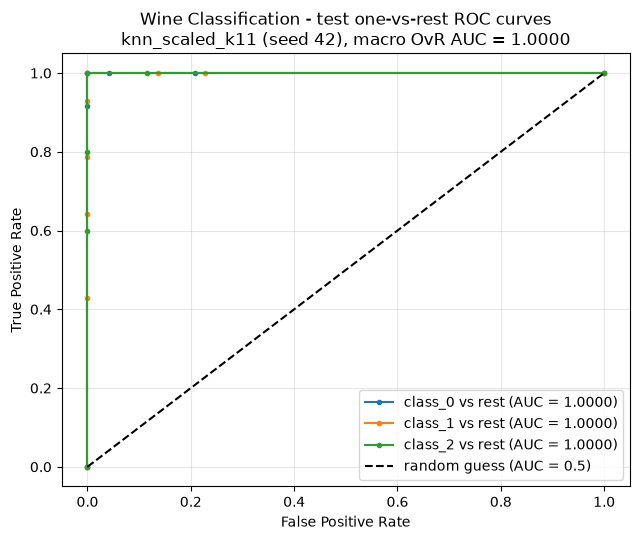

AUC class_0: 1.0000
AUC class_1: 1.0000
AUC class_2: 1.0000
Macro one-vs-rest AUC: 1.0000


In [83]:
plt.figure(figsize=(6.5, 5.5))

class_auc = {}
classes_list = list(final_model.classes_)

for column in range(len(classes_list)):
    label = classes_list[column]
    name = class_names[label]

    one_vs_rest_target = (y_test == label).astype(int)
    probs = test_proba[:, column]

    fpr, tpr, thresholds = roc_curve(one_vs_rest_target, probs)
    auc_value = roc_auc_score(one_vs_rest_target, probs)
    class_auc[name] = auc_value

    plt.plot(fpr, tpr, marker=".", label=f"{name} vs rest (AUC = {auc_value:.4f})")

macro_ovr_auc = roc_auc_score(y_test, test_proba, multi_class="ovr", average="macro", labels=classes_list)

plt.plot([0, 1], [0, 1], "k--", label="random guess (AUC = 0.5)")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title(f"Wine Classification - test one-vs-rest ROC curves\n{selected_config} (seed 42), macro OvR AUC = {macro_ovr_auc:.4f}")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f"figures/{DATASET_NAME}_07_roc_test.png", dpi=150)
plt.show()

for name in class_auc:
    print(f"AUC {name}: {class_auc[name]:.4f}")
print(f"Macro one-vs-rest AUC: {macro_ovr_auc:.4f}")

**Yorum (Interpretation):** Üç one-vs-rest ROC eğrisinin AUC değeri de 1.0000, macro OvR AUC = 1.0000. Model her sınıf için o sınıfın örneklerine diğer örneklerden daha yüksek olasılık verdi.
**Eşik etkisi:** Bir sınıf için "bu sınıftır" demek için gereken olasılık eşiği düşürülürse daha çok örnek o sınıfa atanır. False negative azalır ama false positive artar.
Eşik yükseltilirse tersi olur. Test setiyle eşik seçilmedi veya model ayarlanmadı.

### 9.4 Error interpretation
Test setindeki tüm yanlış sınıflandırmaları listeliyoruz. Örnek olarak listedeki **ilk** (en küçük satır indeksli) hata incelenir;
"en ilginç" hatayı seçmiyoruz.

In [84]:
actual_labels = [class_names[v] for v in y_test]
predicted_labels = [class_names[v] for v in test_pred]

test_results = pd.DataFrame({
    "actual": actual_labels,
    "predicted": predicted_labels
}, index=y_test.index)

for column, label in enumerate(final_model.classes_):
    col_name = f"P({class_names[label]})"
    test_results[col_name] = test_proba[:, column].round(4)

errors = test_results[test_results["actual"] != test_results["predicted"]].sort_index()

errors.to_csv(f"results/supporting/{DATASET_NAME}_test_errors.csv")

print(f"Number of test errors: {len(errors)} of {len(test_results)}")

errors

Number of test errors: 0 of 36


,actual,predicted,P(class_0),P(class_1),P(class_2)


In [85]:
if len(errors) == 0:
    print("The selected classifier made no test errors.")
else:
    example_index = errors.index[0]

    actual_name = errors.loc[example_index, "actual"]
    predicted_name = errors.loc[example_index, "predicted"]

    print(f"Example row index: {example_index} | actual: {actual_name} | predicted: {predicted_name}")

    actual_label = class_names.index(actual_name)
    predicted_label = class_names.index(predicted_name)

    train_42_X = splits[42]["X_train"]
    train_42_y = splits[42]["y_train"]

    actual_mean = train_42_X[train_42_y == actual_label].mean()
    predicted_mean = train_42_X[train_42_y == predicted_label].mean()

    comparison = pd.DataFrame({
        "value": X_test.loc[example_index],
        f"train_mean_{actual_name}": actual_mean,
        f"train_mean_{predicted_name}": predicted_mean
    })

    diff_actual = (comparison["value"] - comparison[f"train_mean_{actual_name}"]).abs()
    diff_predicted = (comparison["value"] - comparison[f"train_mean_{predicted_name}"]).abs()

    closer_to_actual = diff_actual < diff_predicted
    comparison["closer_to"] = np.where(closer_to_actual, actual_name, predicted_name)

    predicted_count = (comparison["closer_to"] == predicted_name).sum()
    total_features = len(comparison)

    print(f"Features closer to the PREDICTED class mean: {predicted_count} of {total_features}")

    display(comparison.round(4))

The selected classifier made no test errors.


**Yorum (Interpretation):** Seçilen sınıflandırıcı test setinde **hiç hata yapmadı** (0/36), bu yüzden gerçek bir yanlış sınıflandırma örneği yok.
Bu sonuç mükemmel genellemeyi kanıtlamaz. Test seti sadece 36 örnek ve tek bir sabit bölünme. Aynı konfigürasyon seed 62 doğrulama setinde
macro-F1 = 0.944 aldı, yani başka örneklerde hata yapabildiği zaten görüldü. 36 örnekte bir hata bile accuracy'yi yaklaşık 2.8 puan düşürürdü.

**Sınırlılıklar:** Doğrulama setleri çok küçük (18 örnek). Bu yüzden k=5, 7 ve 11 arasında ayrım yapılamadı ve seçim eşitlik kuralıyla yapıldı.
Eğitim/doğrulama tekrarları örtüşüyor. Final testte önceden seçilmiş tek seed (42) değerlendirildi.

## 10. K-Means Clustering

K-Means **gözetimsiz (unsupervised)** bir yöntemdir: `fit` sırasında etiket görmez. Bulduğu küme numaraları (cluster IDs)
sınıf etiketi değildir. Bu veri seti için `n_clusters=3` (sınıf sayısına göre sabit bir karşılaştırma ayarı; aramayla seçilmedi),
`random_state=seed`, `n_init=10` kullanılır. `n_init=10`, her fit içinde 10 farklı başlangıç merkezi denenip en iyisinin
(en düşük inertia) tutulması demektir; 10 ayrı deney değildir.

### 10.1 Fit the clustering model
3 seed × 2 temsil = **6 K-Means fit**. Sınıflandırıcılarla aynı eğitim indeksleri kullanılır.

In [86]:
kmeans_runs, kmeans_models = helpers.run_kmeans_experiments(DATASET_NAME, splits, SEEDS, n_clusters=3)
print("Number of K-Means fits:", len(kmeans_runs))
assert len(kmeans_runs) == 6
kmeans_runs.round(4)

Number of K-Means fits: 6


,dataset,run_id,seed,representation,n_clusters,n_init,train_inertia,val_ari,val_silhouette
0,wine,wine_kmeans_unscaled_s42,42,unscaled,3,10,1.350496e+06,0.2828,0.4870
1,wine,wine_kmeans_scaled_s42,42,scaled,3,10,8.747391e+02,1.0000,0.2516
2,wine,wine_kmeans_unscaled_s52,52,unscaled,3,10,1.303675e+06,0.4006,0.5559
3,wine,wine_kmeans_scaled_s52,52,scaled,3,10,8.904355e+02,1.0000,0.3010
4,wine,wine_kmeans_unscaled_s62,62,unscaled,3,10,1.390754e+06,0.4006,0.6867
5,wine,wine_kmeans_scaled_s62,62,scaled,3,10,8.722466e+02,1.0000,0.2726


In [87]:
kmeans_summary = kmeans_runs.groupby("representation").agg(
    train_inertia_mean=("train_inertia", "mean"),
    train_inertia_std=("train_inertia", "std"),
    val_ari_mean=("val_ari", "mean"),
    val_ari_std=("val_ari", "std"),
    val_silhouette_mean=("val_silhouette", "mean"),     # NaN (N/A) değerler ortalamaya katılmaz
    val_silhouette_std=("val_silhouette", "std"),
    n_valid_silhouette=("val_silhouette", "count"),
    n_seeds=("seed", "count"),
).reindex(["unscaled", "scaled"]).reset_index()
kmeans_summary.insert(0, "dataset", DATASET_NAME)
kmeans_summary.round(4)

,dataset,representation,train_inertia_mean,train_inertia_std,val_ari_mean,val_ari_std,val_silhouette_mean,val_silhouette_std,n_valid_silhouette,n_seeds
0,wine,unscaled,1.348308e+06,43580.9098,0.3613,0.068,0.5765,0.1014,3,3
1,wine,scaled,8.791404e+02,9.8609,1.0000,0.000,0.2751,0.0248,3,3


Not: Inertia (küme içi kareler toplamı) özelliklerin birimine bağlıdır. Scaled ve unscaled uzaylardaki inertia değerleri
aynı birimde olmadığından doğrudan karşılaştırılmaz; yalnızca aynı temsil içinde seed'ler arasında karşılaştırılabilir.

### 10.2 Final cluster evaluation on the fixed test sets
Seed 42 ile **zaten eğitilmiş** iki K-Means modeli test setinde `predict` ile kullanılır (yeni fit yok).
İki temsil de raporlanır; daha iyi olanı seçmiyoruz.

In [88]:
kmeans_test_rows = []
test_clusters = {}
for representation in ["unscaled", "scaled"]:
    if representation == "scaled":
        X_test_rep = X_test_scaled
    else:
        X_test_rep = X_test
    clusters = kmeans_models[representation].predict(X_test_rep)
    test_clusters[representation] = clusters
    ari, silhouette = helpers.cluster_scores(X_test_rep, y_test, clusters)
    counts = pd.Series(clusters).value_counts().sort_index()
    kmeans_test_rows.append({
        "dataset": DATASET_NAME,
        "representation": representation,
        "evaluation_seed": TEST_SEED,
        "n_test_samples": len(clusters),
        "cluster_counts": counts.to_dict(),
        "test_ari": ari,
        "test_silhouette": silhouette,
    })
kmeans_test_table = pd.DataFrame(kmeans_test_rows)
kmeans_test_table.round(4)

,dataset,representation,evaluation_seed,n_test_samples,cluster_counts,test_ari,test_silhouette
0,wine,unscaled,42,36,"{0: 14, 1: 10, 2: 12}",0.3733,0.4929
1,wine,scaled,42,36,"{0: 13, 1: 13, 2: 10}",0.9088,0.2711


In [89]:
for representation in ["unscaled", "scaled"]:
    actual_labels = [class_names[v] for v in y_test]
    table = pd.crosstab(pd.Series(actual_labels, name="actual class"),
                        pd.Series(test_clusters[representation], name="cluster ID"))
    print(f"\n{DATASET_NAME} - {representation} - seed 42 - TEST set")
    display(table)
    table.to_csv(f"results/supporting/{DATASET_NAME}_kmeans_contingency_{representation}.csv")


wine - unscaled - seed 42 - TEST set


cluster ID,0,1,2
actual class,,,
class_0,2,10,0
class_1,5,0,9
class_2,7,0,3



wine - scaled - seed 42 - TEST set


cluster ID,0,1,2
actual class,,,
class_0,12,0,0
class_1,1,13,0
class_2,0,0,10


ARI (Adjusted Rand Index), iki bölümlemenin (gerçek sınıflar ve kümeler) ne kadar uyuştuğunu şans etkisini düzelterek ölçer;
küme numaralarının sınıf numaralarıyla aynı olmasını gerektirmez. Etiketler sadece **değerlendirmede** kullanılır.
Burada sınıf etiketleri ile küme numaralarını doğrudan karşılaştıran accuracy veya sınıflandırma confusion matrix'i **hesaplanmaz**.

### 10.3 Visualise and interpret the clusters
Grafik için iki orijinal özellik **seed 42 eğitim verisi** ile seçilir: ANOVA F-skoru (`f_classif`) en yüksek özellik birinci seçilir;
ikinci özellik, birinciyle eğitim verisindeki mutlak korelasyonu 0.7'den küçük olanlar arasında F-skoru en yüksek olandır
(çok benzer iki özellik seçip düz bir çizgi görmemek için). Aynı iki özellik her iki temsil için kullanılır.

In [90]:
train_42 = splits[42]["X_train"]
f_scores, _ = f_classif(train_42, splits[42]["y_train"])
f_scores = pd.Series(f_scores, index=X.columns).sort_values(ascending=False)
feature_1 = f_scores.index[0]
train_correlation = train_42.corr()[feature_1].abs()
feature_2 = None
for f in f_scores.index:
    if f != feature_1 and train_correlation[f] < 0.7:
        feature_2 = f
        break
print("Chosen features (seed-42 training data):", feature_1, "and", feature_2)
print("F-scores: %.1f and %.1f, |r| between them = %.3f" % (f_scores[feature_1], f_scores[feature_2], train_correlation[feature_2]))

Chosen features (seed-42 training data): flavanoids and proline
F-scores: 195.0 and 141.3, |r| between them = 0.540


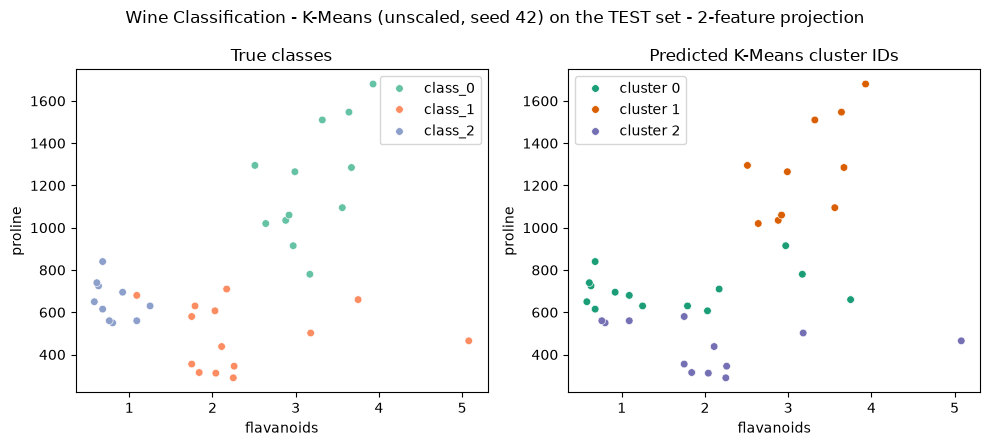

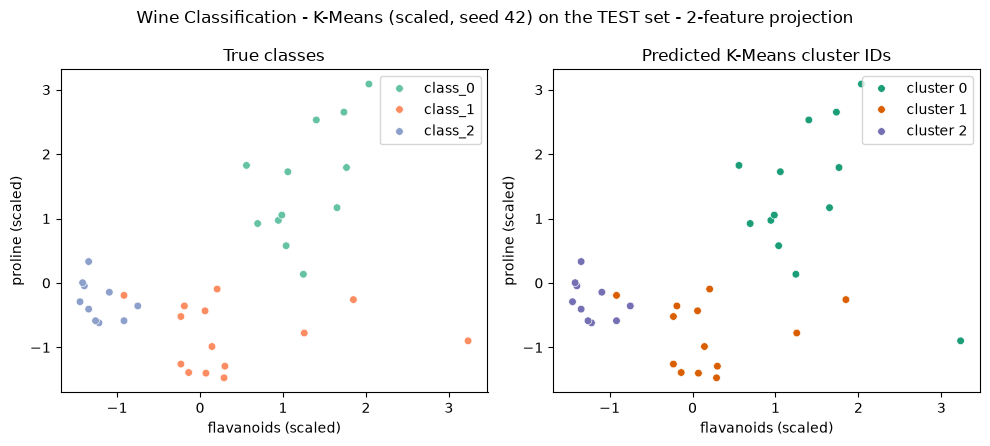

In [91]:
for representation in ["unscaled", "scaled"]:
    if representation == "scaled":
        X_test_rep = X_test_scaled
        suffix = " (scaled)"
    else:
        X_test_rep = X_test
        suffix = ""

    fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))

    true_names = [class_names[v] for v in y_test]
    sns.scatterplot(x=X_test_rep[feature_1], y=X_test_rep[feature_2], hue=true_names,
                    hue_order=class_names, palette="Set2", ax=axes[0], s=30)
    axes[0].set_title("True classes")

    cluster_names = [f"cluster {c}" for c in test_clusters[representation]]
    sns.scatterplot(x=X_test_rep[feature_1], y=X_test_rep[feature_2], hue=cluster_names,
                    hue_order=sorted(set(cluster_names)), palette="Dark2", ax=axes[1], s=30)
    axes[1].set_title("Predicted K-Means cluster IDs")

    for ax in axes:
        ax.set_xlabel(feature_1 + suffix)
        ax.set_ylabel(feature_2 + suffix)

    fig.suptitle(f"Wine Classification - K-Means ({representation}, seed 42) on the TEST set - 2-feature projection")
    fig.tight_layout()
    fig.savefig(f"figures/{DATASET_NAME}_08_kmeans_{representation}_test.png", dpi=150)
    plt.show()

**Yorum (Interpretation):** - **Doğrulama (6 fit):** Ortalama ARI unscaled'da 0.3613 (std 0.068), scaled'da 1.0000 (std 0.000). Scaled K-Means üç seed'in doğrulama setlerinde de
  sınıflarla birebir aynı bölümlemeyi buldu. Silhouette üç seed'de de tanımlı (3/3). Unscaled 0.5765, scaled 0.2751; farklı uzaylarda olduğu için doğrudan karşılaştırılmaz.
- **Test (seed 42):** Unscaled kümeler 14/10/12, ARI = 0.3733. Çapraz tabloda cluster 1 sadece class_0 örneklerinden oluşuyor (10), ama
  class_1 (5 + 9) ve class_2 (7 + 3) cluster 0 ve cluster 2 arasında dağılmış, yani karışık. Scaled kümeler 13/13/10, ARI = 0.9088.
  class_0'ın 12 örneği cluster 0'da, class_2'nin 10 örneği cluster 2'de, class_1'in 13 örneği cluster 1'de; sadece 1 class_1 örneği cluster 0'a düşmüş.
- **Grafikler:** Seed-42 eğitim verisiyle seçilen özellikler **flavanoids** ve **proline**. Unscaled grafikte kümeler neredeyse yatay
  proline bantları şeklinde. K-Means pratikte sadece proline'a bakıyor, bu yüzden class_1 ve class_2 karışıyor. Scaled grafikte kümeler gerçek sınıflara çok benziyor.
  Model 13 özelliğin hepsini kullandı; grafik sadece iki özelliğe izdüşüm.
- **Bilgi farkı:** Sınıflandırıcılar eğitimde etiketleri (`y_train`) kullanarak sınıfları ayırmayı öğrenir. K-Means etiketleri hiç görmez;
  sadece mesafeye ve sabit küme sayısına (k=3) göre gruplar. Buna rağmen ölçeklenmiş Wine verisinde kümeler sınıflara çok yakın çıktı.
  Bu, Wine sınıflarının özellik uzayında doğal olarak ayrık gruplar oluşturduğunu gösteriyor.

## 12. Required Run and Output Inventory (this dataset)

Bu bölüm bu veri setinin sonuçlarını iki veri setinin **ortak** CSV dosyalarına (`results/` klasörü) yazar ve sayıları kontrol eder.
Her CSV'de `dataset` sütunu vardır. Diğer notebook da kendi satırlarını aynı dosyalara ekler.
Destekleyici tablolar (betimleyici istatistikler, bölünme özeti, sınıflandırma raporu, confusion matrix, elle hesap, çapraz tablolar)
yukarıdaki hücrelerde `results/supporting/` klasörüne kaydedildi.
Bölüm 11 (iki veri setinin karşılaştırması) her iki notebook'un sonucuna ihtiyaç duyduğu için `report.docx` içindedir.

In [92]:
outputs = {
    "classifier_runs.csv": run_table[["dataset"] + run_columns + ["config_id", "val_undefined_before_zero_division"]],
    "classifier_summary.csv": summary_table.drop(columns=["setting"]),
    "classifier_test.csv": final_test_table,
    "kmeans_runs.csv": kmeans_runs,
    "kmeans_summary.csv": kmeans_summary,
    "kmeans_test.csv": kmeans_test_table,
}

for file_name, table in outputs.items():
    helpers.save_combined_csv(table, file_name, DATASET_NAME)
    print(file_name, ":", len(table), "rows for", DATASET_NAME)

total_fits = len(run_table) + len(kmeans_runs)
print("\nModel fits in this notebook:", len(run_table), "classifier +", len(kmeans_runs), "K-Means =", total_fits)

figure_files = []
for f in os.listdir("figures"):
    if f.startswith(DATASET_NAME):
        figure_files.append(f)
print("Figure files for this dataset:", sorted(figure_files))

classifier_runs.csv : 66 rows for wine
classifier_summary.csv : 22 rows for wine
classifier_test.csv : 1 rows for wine
kmeans_runs.csv : 6 rows for wine
kmeans_summary.csv : 2 rows for wine
kmeans_test.csv : 2 rows for wine

Model fits in this notebook: 66 classifier + 6 K-Means = 72
Figure files for this dataset: ['wine_01_class_distribution.png', 'wine_02_correlation_heatmap.png', 'wine_03_boxplots_part1.png', 'wine_04_tree_depth_comparison.png', 'wine_05_knn_neighbors_comparison.png', 'wine_06_confusion_matrix_test.png', 'wine_07_roc_test.png', 'wine_08_kmeans_scaled_test.png', 'wine_08_kmeans_unscaled_test.png']
